# **Image Transformation**

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.util import invert
from skimage.color import rgb2gray
from skimage.filters import sobel, gaussian
from skimage.exposure import rescale_intensity
from skimage import io, data, img_as_ubyte, img_as_float

**1 Image Representation**

In [3]:
im = data.camera()
print(im[250:260,250:260])

[[ 5  4  5  6  5  5  6  5  5  6]
 [ 4  5  5  6  5  5  4  5  5  8]
 [ 6  5  5  6  6  4  6  5  6 10]
 [ 5  5  5  5  6  4  5  5  5  9]
 [ 4  5  5  5  5  5  5  5  6  8]
 [ 4  5  6  5  5  5  7  7  6  7]
 [ 4  5  6  5  6  8 14  8  5  5]
 [ 5  5  5  6  9 15 17  9  5  4]
 [ 5  6  8 11 16 18 15 10  5  5]
 [ 7 11 15 17 18 19 16  9  4  5]]


*#* Multiply

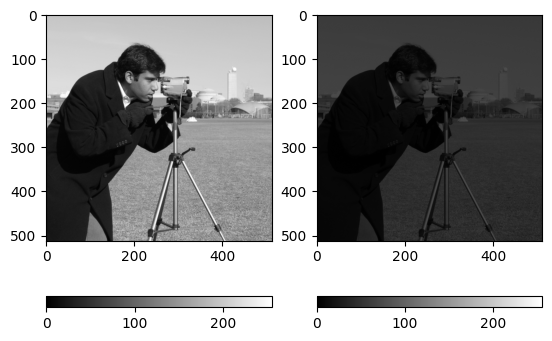

In [4]:
im = data.camera()
imf = 0.3 * im
imf = imf.astype(np.uint8)

fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imf, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

**2 Mix**

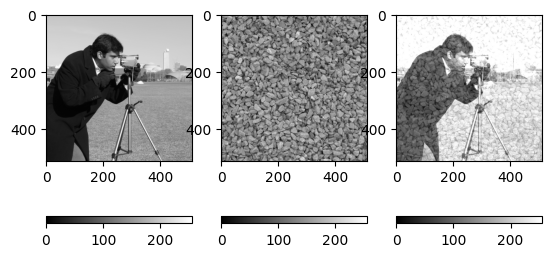

In [6]:
ima = data.camera()
imb = data.gravel()
im = ima.astype(float) + 0.5 * imb.astype(float)

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(ima, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(imb, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

**3 Addition**

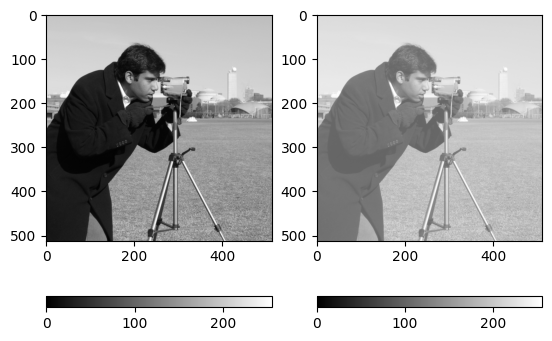

In [7]:
im = data.camera()
c = 100
imf = (rescale_intensity(im, out_range=(c, 255))).astype(np.uint8)

fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imf, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

**4 Blending**

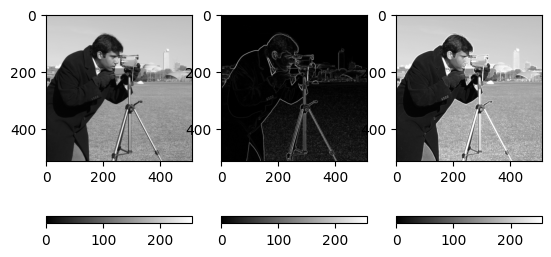

In [8]:
im = data.camera()
img = sobel(im)
img = rescale_intensity(img, out_range=(0, 255))
imb = im + img

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(ima, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(img, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imb, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

*#* Subtraction

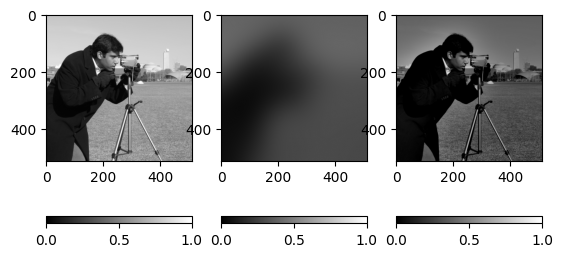

In [9]:
im0 = img_as_float(data.camera())
im1 = gaussian(im0, sigma=50)/2
ims = im0 - im1
ims[ims<0] = 0

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im0, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im1, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(ims, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

**5 Subtraction - move**

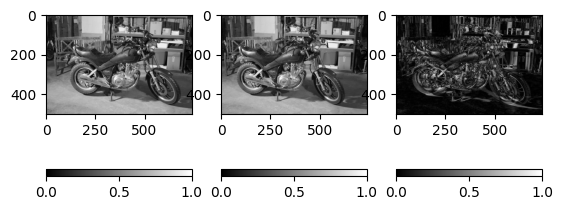

In [10]:
im0, im1, _ = data.stereo_motorcycle()
im0 = rgb2gray(im0)
im1 = rgb2gray(im1)
ims = np.abs(im0 - im1)

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im0, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im1, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(ims, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

**6 Division**

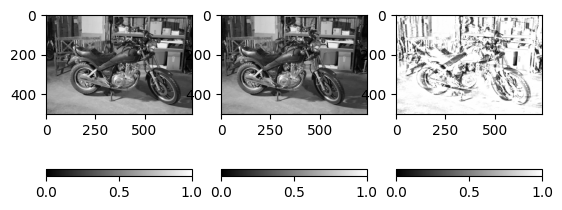

In [11]:
im0, im1, _ = data.stereo_motorcycle()
im0 = rgb2gray(im0)
im1 = rgb2gray(im1)
im0 = img_as_float(im0)
im1 = img_as_float(im1)
imd = np.zeros_like(im0)
imd[im1!=0] = im0[im1!=0] / im1[im1!=0]

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im0, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im1, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imd, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

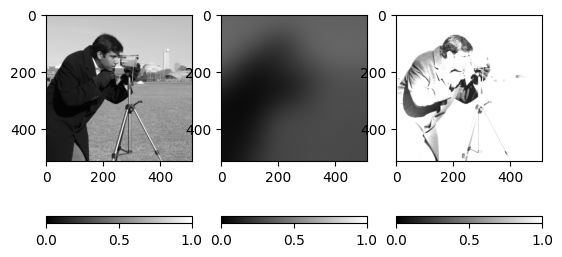

In [13]:
im0 = img_as_float(data.camera())
im1 = gaussian(im0, sigma=50)/2
imd = np.zeros_like(im0)
imd[im1!=0] = im0[im1!=0] / im1[im1!=0]

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im0, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im1, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imd, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 1)

**7 Mutliplication**

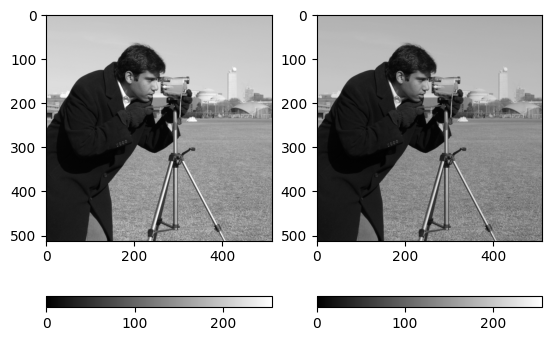

In [20]:
im = data.camera()
imm = 0.3 * im
imm = 3 * imm
imm = imm.astype(np.uint8)

fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imm, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

*#*  NOT

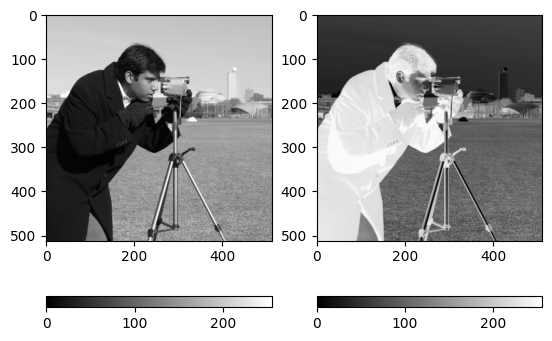

In [15]:
im = data.camera()
imn = invert(im)

fig = plt.figure()
ax = fig.add_subplot(1, 2, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 2, 2)
p = plt.imshow(imn, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

**8 AND**

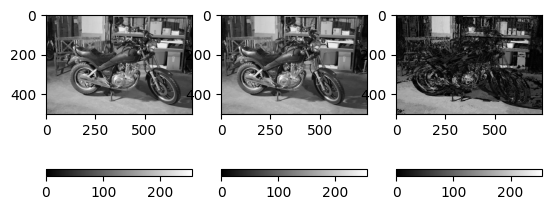

In [16]:
im0, im1, _ = data.stereo_motorcycle()
im0 = rgb2gray(im0)
im1 = rgb2gray(im1)
im0 = img_as_ubyte(im0)
im1 = img_as_ubyte(im1)
im = np.bitwise_and(im0, im1)

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im0, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(im1, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

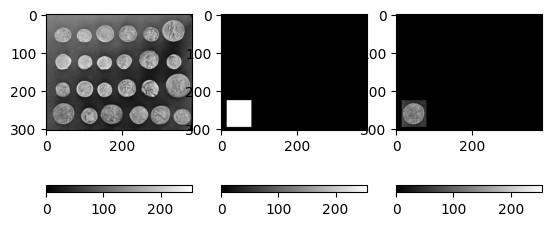

In [17]:
im = data.coins()
imm = np.zeros_like(im)
imm[225:295,15:80] = 255
ima = im.copy()
ima[imm==0] = 0

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(imm, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(ima, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

**9 OR**

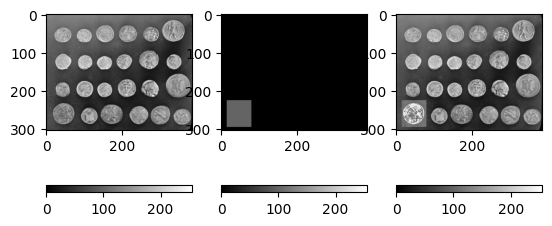

In [18]:
im = data.coins()
imm = np.zeros_like(im)
imm[225:295,15:80] = 100
imor = np.bitwise_or(im, imm)

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(imm, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imor, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

**10 XOR**

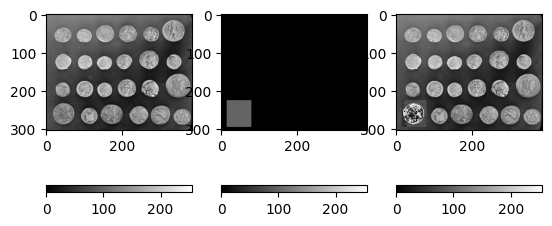

In [19]:
im = data.coins()
imm = np.zeros_like(im)
imm[225:295,15:80] = 100
imxor = np.bitwise_xor(im, imm)

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(imm, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imxor, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)